## DNA Sequence Alignment

## Install Biopython

In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 66.5 MB/s eta 0:00:00


**Read a sequence from a FASTA file**



In [ ]:
def read_sequence(filename):
  genome = ""
  with open(filename, 'r') as f:
    for line in f:
      if line[0] != ">":
        genome += line.rstrip() # trims whitespace, new line character, etc.
  return genome

In [ ]:
# lambda virus genome

genome = read_sequence("lambda_virus.fa")
genome

'...'

In [ ]:
# 48592 bases long

len(genome)

48502

## **BLAST**

**B**asic **L**ocal **A**Lignment **S**earch **T**ool

BLAST performs sequence alignment

### Database searching

Will try to find the genome sequences in the databases that are the most similar to our genome.

In [ ]:
from Bio.Blast import NCBIWWW

In [ ]:
fasta_string = open("lambda_virus.fa").read()

In [ ]:
result_handle = NCBIWWW.qblast("blastn", "nt", fasta_string)

In [ ]:
from Bio.Blast import NCBIXML
blast_records = NCBIXML.parse(result_handle)

In [ ]:
for b in blast_records:
  for alignment in b.alignments:
    for hsp in alignment.hsps:
      print("**** ALIGNMENT ****")
      print("sequence: ", alignment.title)
      print("length: ", alignment.length)
      print("e value: ", hsp.expect)
      print(hsp.query[:75] + '...')
      print(hsp.match[:75] + '...')
      print(hsp.sbjct[:75] + '...')

# According to the data output: the best match is from a strain of the bacterium E coli

**** ALIGNMENT ****
sequence:  gi|9626243|ref|NC_001416.1| Enterobacteria phage lambda, complete genome >gi|215104|gb|J02459.1|LAMCG Escherichia phage Lambda, complete genome
length:  48502
e value:  0.0
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCGTTTCCGTTCTTCTTCGTCATA...
|||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||...
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCGTTTCCGTTCTTCTTCGTCATA...
**** ALIGNMENT ****
sequence:  gi|2196324184|gb|OM475435.1| Escherichia phage E26-Berryhill, partial genome
length:  48850
e value:  0.0
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCGTTTCCGTTCTTCTTCGTCATA...
|||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||...
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTTTCCGGTTTAAGGCGTTTCCGTTCTTCTTCGTCATA...
**** ALIGNMENT ****
sequence:  gi|2196324184|gb|OM475435.1| Escherichia phage E26-Berryhill, partial genome
length:  48850
e value:  2.49072e-78
GGGCGGCGACCTCGCGGGTTTTCGCTATTTATGAAAATTT

## **Genomic Data Analysis**

In [ ]:
from Bio import SeqIO

# Read the DNA sequence
DNA = SeqIO.read('MN908947.fna',"fasta")

### DNA

In [ ]:
DNA_seq = str(DNA.seq)
print(DNA.seq)

...


### Sequence Length

Number of nucleotides(bases)

In [ ]:
len(DNA.seq)

29903

**Distribution of Nucleotides**

In [ ]:
count_nucleotides = {
    "A": DNA_seq.count("A"),
    "C": DNA_seq.count("C"),
    "G": DNA_seq.count("G"),
    "T": DNA_seq.count("T")
}

print(count_nucleotides)

{'A': 8954, 'C': 5492, 'G': 5863, 'T': 9594}


**Visualize nucleotide distribution**

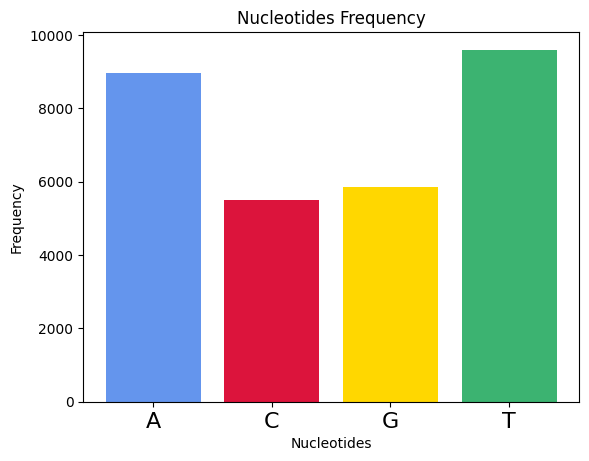

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.bar(count_nucleotides.keys(), count_nucleotides.values(), color = ["cornflowerblue", "crimson", "gold", "mediumseagreen"])
ax.set_xlabel("Nucleotides")
ax.set_ylabel("Frequency")
ax.set_title("Nucleotides Frequency")
ax.tick_params(axis = "x", labelsize = 16)
plt.show()

### **GC content**

GC content is the percentage of guanine and cytosine nitrogenous bases in a DNA or RNA sequence. Measuring GC content can provide useful insights, one of wihch is in designing primers. Primers with a GC content of around 40% - 60% are generally preferred because they have a melting point that is suitable for PCR. In polymerase chain reaction (PCR) experiments, the GC-content of short oligonucleotides known as primers is often used to predict their annealing temperature to the template DNA. A higher GC-content level indicates a relatively higher melting temperature.

In [ ]:
from Bio.SeqUtils import gc_fraction
print(f"GC Content of DNA sequence: {100 * gc_fraction(DNA.seq):.2f}%")

GC Content of DNA sequence: 37.97%


### **Transcription**

### mRNA

In [ ]:
mRNA_sequence = DNA.seq.transcribe()
print(mRNA_sequence[:50])

AUUAAAGGUUUAUACCUUCCCAGGUAACAAACCAACCAACUUUCGAUCUC


### DNA ---> mRNA

First 50 bases

In [ ]:
print(DNA_seq[:50])
print(mRNA_sequence[:50])

ATTAAAGGTTTATACCTTCCCAGGTAACAAACCAACCAACTTTCGATCTC
AUUAAAGGUUUAUACCUUCCCAGGUAACAAACCAACCAACUUUCGAUCUC


## Translation

### Amino Acids

**There are several amino acid chains separated by stop codons**

An open reading frame is a portion of a DNA molecule that, when translated into amino acid, containing no stop codons.

In [ ]:
# Translate the mRNA sequence to a chain of amino acids
amino_acids = mRNA_sequence.translate()
print(amino_acids[:50])

IKGLYLPR*QTNQLSISCRSVL*TNFKICVAVTRLHA*CTHAV*LITNYC


/usr/local/lib/python3.12/dist-packages/Bio/Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


**The genome has 9967 amino acids**

In [ ]:
len(amino_acids)

**Top-10 Amino Acids**

In [ ]:
# Count the frequency of amino acids

from collections import Counter
amino_acids_count = Counter(amino_acids).most_common(10)
# L = Leucine

In [ ]:
top_aa = Counter(amino_acids).most_common(11)
aa_counts = [count for letter, count in top_aa if letter != "*"]
aa_letters = [letter for letter, count in top_aa if letter != "*"]

**Visualize Distribution of Top-10 Amino Acids**

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
#ax.bar(aa_letters, aa_counts, color = ["cornflowerblue", "crimson", "gold", "mediumseagreen"])
colors = cm.tab20.colors[:len(aa_letters)]
ax.bar(aa_letters, aa_counts, color=colors)

ax.set_xlabel("Amino Acids")
ax.set_ylabel("Frequency")
ax.set_title("Amino Acids Frequency")
ax.tick_params(axis = "x", labelsize = 16)
plt.show()

## Proteins

**Split on stop codon**

In [ ]:
# proteins = [str(i) for i in amino_acids.split("*")]
# print(proteins)

In [ ]:
# Split on stop codon to string
proteins = amino_acids.splt("*")
print(proteins)

**Number of Proteins**

In [ ]:
len(proteins)

**Length of various amino acids sequences**

In [ ]:
import pandas as pd
df = pd.DataFrame({"Amino Acids": covid_proteins})
df["Count"] = df["Amino Acids"].str.len()
df.head(10)

**Top-10 longest amino acids sequences**

In [ ]:
df.nlargest(n=10, columns="Count")